## ДЗ №3 Двухуровневый пайплайн
#### В этой домашке вам предстоит написать с нуля двустадийную рекомендательную систему. 


### Описание
Это творческое задание, в котором вам необходимо реализовать полный цикл построения рекомендательной системы: реализовать кандидат генераторов, придумать и собрать признаки, обучить итоговый ранкер и заинференсить модели на всех пользователей.

Вам предоставляется два набора данных: `train.csv` и `test.csv` 

In [1]:
# скачиваем данные (те же файлы Google Drive, что в исходной ячейке) в data/final/, если их ещё нет
# если из этой ячейки не получается, то вот ссылка на папку https://drive.google.com/drive/folders/1HT0Apm8Jft0VPLJtdBBUGu9s1M7vZcoJ?usp=drive_link
import os
DATA = os.path.join('data', 'final')
os.makedirs(DATA, exist_ok=True)
FILES = {'train.csv': '1-CcS22-UpTJeNcFlA0dVLrEQn8jnI0d-', 'test.csv': '11iz3xDh0IIoEIBY0dyRSvByY3qfiT3BG',
         'users.csv': '1zl2jWMdUhc-IMakHlihQhJ5PGGZm9-_O', 'items.csv': '1chCmpiCKJRjdqNftHc-t2ALl3qbAp2G8'}
if not all(os.path.exists(os.path.join(DATA, f)) for f in FILES):
    import gdown   # pip install gdown
    for name, fid in FILES.items():
        if not os.path.exists(os.path.join(DATA, name)):
            gdown.download(f'https://drive.google.com/uc?id={fid}', os.path.join(DATA, name), quiet=True)
OUT = os.path.join('data', 'final_outputs')
os.makedirs(OUT, exist_ok=True)
print({f: f'{os.path.getsize(os.path.join(DATA, f)) / 2**20:.1f} MB' for f in sorted(os.listdir(DATA))})

{'items.csv': '30.4 MB', 'test.csv': '20.1 MB', 'train.csv': '162.0 MB', 'users.csv': '28.6 MB'}


In [2]:
import pandas as pd
pd.read_csv(os.path.join(DATA, 'users.csv'))

,user_id,age,income,sex,kids_flg
0,973171,age_25_34,income_60_90,М,1
1,962099,age_18_24,income_20_40,М,0
2,1047345,age_45_54,income_40_60,Ж,0
3,721985,age_45_54,income_20_40,Ж,0
4,704055,age_35_44,income_60_90,Ж,0
...,...,...,...,...,...
840192,339025,age_65_inf,income_0_20,Ж,0
840193,983617,age_18_24,income_20_40,Ж,1
840194,251008,NaN,NaN,NaN,0
840195,590706,NaN,NaN,Ж,0


In [3]:
import time, gc, warnings
%matplotlib inline
import numpy as np
import pandas as pd
import scipy.sparse as sps
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from threadpoolctl import threadpool_limits
import torch
import torch.nn as nn
import torch.nn.functional as F
from implicit.als import AlternatingLeastSquares

warnings.filterwarnings('ignore')
threadpool_limits(1, 'blas')
SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
QUICK = bool(int(os.environ.get('RECSYS_QUICK', '0')))   # отладочный прогон на подвыборке пользователей
DEVICE = 'mps' if torch.backends.mps.is_available() else 'cpu'
torch.set_num_threads(os.cpu_count())
print('device:', DEVICE, '| cpu:', os.cpu_count(), '| quick:', QUICK)

def timer(msg, t0=[time.time()]):
    print(f'[{time.time() - t0[0]:7.1f}s] {msg}', flush=True)

device: mps | cpu: 16 | quick: False


In [4]:
train = pd.read_csv(os.path.join(DATA, 'train.csv'))
test = pd.read_csv(os.path.join(DATA, 'test.csv'))
users = pd.read_csv(os.path.join(DATA, 'users.csv'))
items = pd.read_csv(os.path.join(DATA, 'items.csv'))
for name, d in [('train', train), ('test', test), ('users', users), ('items', items)]:
    print(f'{name}: {d.shape}, columns: {list(d.columns)}')
train.head()

train: (4866956, 6), columns: ['user_id', 'item_id', 'last_watch_dt', 'total_dur', 'watched_pct', 'target']
test: (608467, 6), columns: ['user_id', 'item_id', 'last_watch_dt', 'total_dur', 'watched_pct', 'target']
users: (840197, 5), columns: ['user_id', 'age', 'income', 'sex', 'kids_flg']
items: (15963, 14), columns: ['item_id', 'content_type', 'title', 'title_orig', 'release_year', 'genres', 'countries', 'for_kids', 'age_rating', 'studios', 'directors', 'actors', 'description', 'keywords']


,user_id,item_id,last_watch_dt,total_dur,watched_pct,target
0,310745,13373,2021-03-13,4485,98.0,1
1,952323,15997,2021-03-13,7507,100.0,1
2,889459,11460,2021-03-13,60,0.0,0
3,854016,11237,2021-03-13,5381,98.0,1
4,307257,9132,2021-03-13,5814,100.0,1


train: дни 0 - 152 | строк 4866956 | юзеров 880421 | айтемов 15418
test : дни 153 - 162 | строк 608467 | юзеров 216399 | айтемов 7817
холодных юзеров в тесте: 81730 (37.8%), их интеракций: 31.0%
айтемов теста, которых нет в трейне: 187

доля target=1: train 0.440, test 0.349


         min    max  mean
target                   
0        0.0   50.0  12.0
1       51.0  100.0  92.3
target == (watched_pct > 50): True
users.csv покрывает юзеров теста: 0.781


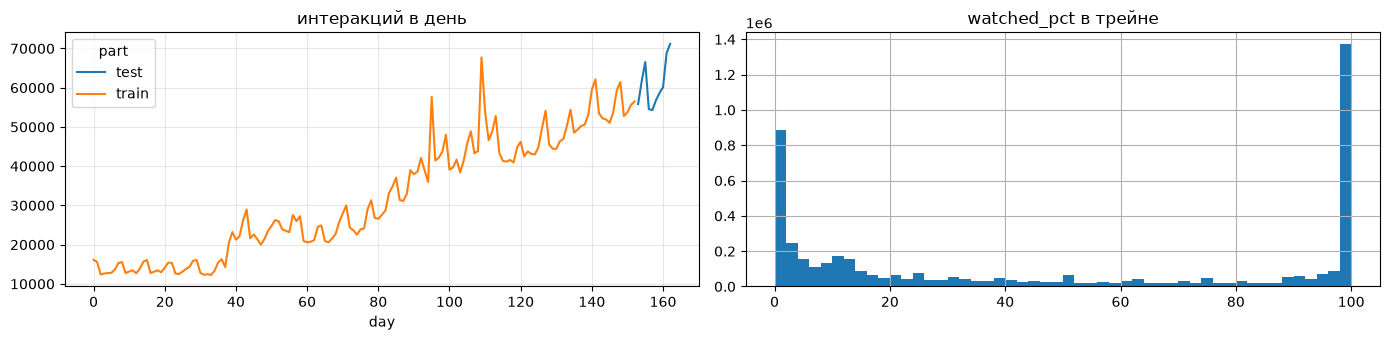

In [5]:
# Даты -> номер дня от начала данных (удобно для окон и «честных» признаков по дням)
DATE0 = pd.to_datetime(train['last_watch_dt']).min()
for d in (train, test):
    d['day'] = (pd.to_datetime(d['last_watch_dt']) - DATE0).dt.days.astype(np.int16)

if QUICK:   # отладка: 15% пользователей
    keep = pd.Series(pd.concat([train.user_id, test.user_id]).unique()).sample(frac=0.15, random_state=SEED)
    train, test = train[train.user_id.isin(keep)].copy(), test[test.user_id.isin(keep)].copy()

train_users_set = set(train.user_id)
test_users = test.user_id.unique()
cold_test_users = np.array([u for u in test_users if u not in train_users_set])
print('train: дни', train.day.min(), '-', train.day.max(), '| строк', len(train), '| юзеров', train.user_id.nunique(), '| айтемов', train.item_id.nunique())
print('test : дни', test.day.min(), '-', test.day.max(), '| строк', len(test), '| юзеров', len(test_users), '| айтемов', test.item_id.nunique())
print(f'холодных юзеров в тесте: {len(cold_test_users)} ({len(cold_test_users) / len(test_users):.1%}), '
      f'их интеракций: {test.user_id.isin(cold_test_users).mean():.1%}')
print('айтемов теста, которых нет в трейне:', len(set(test.item_id) - set(train.item_id)))
# В данных есть готовый таргет: проверим, как он связан с watched_pct
print('\nдоля target=1: train %.3f, test %.3f' % (train.target.mean(), test.target.mean()))
print(train.groupby('target').watched_pct.agg(['min', 'max', 'mean']).round(1))
print('target == (watched_pct > 50):', bool(((train.watched_pct > 50).astype(int) == train.target).all()))
print('users.csv покрывает юзеров теста:', np.isin(test_users, users.user_id).mean().round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
pd.concat([train.assign(part='train'), test.assign(part='test')]).groupby(['day', 'part']).size().unstack().plot(ax=axes[0])
axes[0].set_title('интеракций в день'); axes[0].grid(alpha=0.3)
train.watched_pct.clip(0, 100).hist(bins=50, ax=axes[1]); axes[1].set_title('watched_pct в трейне')
plt.tight_layout(); plt.show()

**Что в данных.**
* `train` — 4.87 млн интеракций (880 тыс. юзеров, 15.4 тыс. айтемов) с 13.03 по 12.08.2021.
* `test` — следующие 10 дней (13–22.08): 608 тыс. интеракций, 216 тыс. юзеров. **37.8% юзеров теста — холодные** (их нет в трейне), на них приходится 31% тестовых интеракций.
* Колонка `target` — это ровно `watched_pct > 50`: доля позитивов 44% в трейне и 35% в тесте. Поэтому `watched_pct` нельзя подавать в модель как признак текущей пары, его можно использовать только в агрегатах по прошлому.

In [6]:
# Единое кодирование юзеров и айтемов (все id из всех таблиц) — индексы общие для всех моделей
all_user_ids = np.unique(np.concatenate([train.user_id, test.user_id, users.user_id]))
all_item_ids = np.unique(np.concatenate([train.item_id, test.item_id, items.item_id]))
uid2idx = pd.Series(np.arange(len(all_user_ids)), index=all_user_ids)
iid2idx = pd.Series(np.arange(len(all_item_ids)), index=all_item_ids)
N_USERS, N_ITEMS = len(all_user_ids), len(all_item_ids)
for d in (train, test):
    d['u'] = uid2idx.loc[d.user_id].values.astype(np.int32)
    d['i'] = iid2idx.loc[d.item_id].values.astype(np.int32)
print('N_USERS =', N_USERS, '| N_ITEMS =', N_ITEMS)

# Разбиение train по времени: последние VALID_DAYS дней — valid_stage_1
VALID_DAYS = 7
valid_start = train.day.max() - VALID_DAYS + 1
train_stage_1 = train[train.day < valid_start].copy()
valid_stage_1 = train[train.day >= valid_start].copy()
print(f'train_stage_1: дни {train_stage_1.day.min()}–{train_stage_1.day.max()}, {len(train_stage_1)} строк')
print(f'valid_stage_1: дни {valid_stage_1.day.min()}–{valid_stage_1.day.max()}, {len(valid_stage_1)} строк, '
      f'{valid_stage_1.user_id.nunique()} юзеров, из них новых: {(~valid_stage_1.user_id.isin(train_stage_1.user_id)).mean():.1%} строк')

N_USERS = 1058084 | N_ITEMS = 15963


train_stage_1: дни 0–145, 4473822 строк
valid_stage_1: дни 146–152, 393134 строк, 156271 юзеров, из них новых: 28.3% строк




### 1 Этап. Модели первого уровня. (max 3 балла)
В этом этапе вам необходимо разделить `train` датасет на 2 части: для обучения моделей первого уровня и для их валидации. Единственное условие для разбиения – разбивать нужно по времени. Данные для обучение будем называть `train_stage_1`, данные для валидации `valid_stage_1`. Объемы этих датасетов вы определяет самостоятельно. 

Для начала нам нужно отобрать кандидатов при помощи легких моделей. Необходимо реализовать 3 типа моделей:
1. Любая эвристическая(алгоритмичная) модель на ваш выбор **(0.5 балл)**
2. Любая матричная факторизация на ваш выбор **(1 балл)**
3. Любая нейросетевая модель на ваш выбор **(1 балла)**

Не забудьте использовать скор каждой модели, как признак!



### Модели первого уровня

Все три модели реализуют одинаковый интерфейс:
* `fit(interactions)` — обучение на интеракциях (колонки `u`, `i`, `day`, `watched_pct`);
* `score(u, i)` — скор релевантности для пар; если модель не знает юзера или айтем, возвращается дефолтное значение `default_score`;
* `recommend(u_array, k)` — top-k айтемов для каждого юзера (без уже просмотренного в данных обучения).

1. **Эвристика — `SegmentPopular`**: популярность за последние 14 дней с экспоненциальным затуханием по давности (полураспад 7 дней), отдельно в каждом сегменте «возраст × пол» из `users.csv`. Работает и для холодных юзеров (берётся их сегмент или общая популярность).
2. **Матричная факторизация — `ALSRecommender`**: iALS из `implicit`, доверие растёт с долей просмотра: `c = 1 + alpha · min(watched_pct, 100) / 100`.
3. **Нейросеть — `MultVAERecommender`**: Mult-VAE (Liang et al., 2018) — вариационный автоэнкодер над вектором просмотров юзера с мультиномиальным правдоподобием. Скор пары — логит декодера; для незнакомого юзера используем выход декодера при `z = 0` (априорная «средняя» популярность).

In [7]:
class SegmentPopular:
    """Эвристика: популярность в сегменте (возраст × пол) за последние window дней с затуханием по давности."""
    name = 'pop'

    def __init__(self, window=14, half_life=7, default_score=0.0):
        self.window, self.half_life, self.default_score = window, half_life, default_score

    def fit(self, inter):
        last = inter.day.max()
        recent = inter[inter.day > last - self.window]
        w = 0.5 ** ((last - recent.day.values) / self.half_life)
        self.global_pop = np.bincount(recent.i.values, weights=w, minlength=N_ITEMS)
        self.global_pop = self.global_pop / self.global_pop.sum()
        seg_codes = USER_SEGMENT[recent.u.values]
        self.seg_pop = np.zeros((N_SEGMENTS, N_ITEMS))
        np.add.at(self.seg_pop, (seg_codes, recent.i.values), w)
        sums = self.seg_pop.sum(axis=1, keepdims=True)
        # сглаживаем сегмент к общей популярности (мелкие сегменты шумные)
        self.seg_pop = (self.seg_pop + 50 * self.global_pop) / (sums + 50)
        self.seen = build_seen(inter)
        self.seg_order = np.argsort(-self.seg_pop, axis=1)[:, :1000]
        return self

    def score(self, u, i):
        s = self.seg_pop[USER_SEGMENT[u], i]
        return np.where(s > 0, s, self.default_score)

    def recommend(self, u_array, k=50):
        out = np.empty((len(u_array), k), dtype=np.int32)
        for r, u in enumerate(u_array):
            seen = self.seen.get(u, ())
            order = self.seg_order[USER_SEGMENT[u]]
            out[r] = [i for i in order[:k + len(seen) + 1] if i not in seen][:k] if seen else order[:k]
        return out


class ALSRecommender:
    """iALS (implicit). Доверие зависит от доли просмотра."""
    name = 'als'

    def __init__(self, factors=128, regularization=0.05, alpha=10, iterations=15, default_score=0.0):
        self.params = dict(factors=factors, regularization=regularization, iterations=iterations)
        self.alpha, self.default_score = alpha, default_score

    def fit(self, inter):
        conf = 1 + self.alpha * inter.watched_pct.clip(0, 100).fillna(0).values / 100
        self.user_items = sps.csr_matrix((conf.astype(np.float32), (inter.u.values, inter.i.values)), shape=(N_USERS, N_ITEMS))
        self.user_items.sum_duplicates()
        self.model = AlternatingLeastSquares(random_state=SEED, **self.params)
        self.model.fit(self.user_items, show_progress=False)
        self.known_users = np.asarray(self.user_items.getnnz(axis=1) > 0)
        self.known_items = np.asarray(self.user_items.getnnz(axis=0) > 0)
        self.U, self.V = self.model.user_factors, self.model.item_factors
        self.pop_items = np.argsort(-np.bincount(inter.i.values, minlength=N_ITEMS))   # для холодных юзеров
        return self

    def score(self, u, i, chunk=500_000):
        u, i = np.asarray(u), np.asarray(i)
        s = np.empty(len(u), dtype=np.float32)
        for b in range(0, len(u), chunk):        # чанками, чтобы не держать в памяти [n_pairs, factors]
            s[b:b + chunk] = np.einsum('ij,ij->i', self.U[u[b:b + chunk]], self.V[i[b:b + chunk]])
        return np.where(self.known_users[u] & self.known_items[i], s, self.default_score)

    def recommend(self, u_array, k=50):
        out = np.full((len(u_array), k), -1, dtype=np.int32)
        known = self.known_users[u_array]
        if known.any():
            uk = u_array[known]
            ids, _ = self.model.recommend(uk, self.user_items[uk], N=k, filter_already_liked_items=True)
            out[known] = ids
        out[~known] = self.pop_items[:k]   # холодного юзера ALS не знает — отдаём популярное из данных обучения
        return out


class MultVAE(nn.Module):
    def __init__(self, n_items, hidden=600, latent=200, dropout=0.5):
        super().__init__()
        self.enc = nn.Linear(n_items, hidden)
        self.mu_logvar = nn.Linear(hidden, 2 * latent)
        self.dec1 = nn.Linear(latent, hidden)
        self.dec2 = nn.Linear(hidden, n_items)
        self.drop = nn.Dropout(dropout)
        self.latent = latent

    def encode(self, x):
        x = F.normalize(x, dim=1)
        h = torch.tanh(self.enc(self.drop(x)))
        mu, logvar = self.mu_logvar(h).chunk(2, dim=1)
        return mu, logvar

    def decode(self, z):
        return self.dec2(torch.tanh(self.dec1(z)))

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = mu + torch.randn_like(mu) * torch.exp(0.5 * logvar) if self.training else mu
        return self.decode(z), mu, logvar


class MultVAERecommender:
    """Нейросетевой генератор: Mult-VAE над бинарным вектором просмотров. Обучаем на айтемах с >= min_item_cnt просмотров."""
    name = 'vae'

    def __init__(self, epochs=15, batch_size=512, lr=1e-3, beta_max=0.2, min_item_cnt=5, default_score=-20.0):
        self.epochs, self.batch_size, self.lr, self.beta_max = epochs, batch_size, lr, beta_max
        self.min_item_cnt, self.default_score = min_item_cnt, default_score

    def _user_rows(self, u_array):
        X = self.X[u_array]
        return torch.as_tensor(X.toarray(), dtype=torch.float32, device=DEVICE)

    def fit(self, inter):
        cnt = np.bincount(inter.i.values, minlength=N_ITEMS)
        self.item_ids = np.where(cnt >= self.min_item_cnt)[0]            # айтемы модели
        self.col_of = np.full(N_ITEMS, -1); self.col_of[self.item_ids] = np.arange(len(self.item_ids))
        d = inter[self.col_of[inter.i.values] >= 0]
        self.X = sps.csr_matrix((np.ones(len(d), dtype=np.float32), (d.u.values, self.col_of[d.i.values])),
                                shape=(N_USERS, len(self.item_ids)))
        self.X.data[:] = 1.0
        self.known_users = np.asarray(self.X.getnnz(axis=1) > 0)
        train_users = np.where(self.known_users)[0]
        self.net = MultVAE(len(self.item_ids)).to(DEVICE)
        opt = torch.optim.Adam(self.net.parameters(), lr=self.lr)
        n_batches = int(np.ceil(len(train_users) / self.batch_size))
        total_steps, step = self.epochs * n_batches, 0
        rng = np.random.default_rng(SEED)
        self.history = []
        for epoch in range(self.epochs):
            self.net.train()
            perm = rng.permutation(train_users)
            ep_loss = 0.0
            for b in range(n_batches):
                x = self._user_rows(perm[b * self.batch_size:(b + 1) * self.batch_size])
                logits, mu, logvar = self.net(x)
                nll = -(F.log_softmax(logits, dim=1) * x).sum(dim=1).mean()
                kl = (-0.5 * (1 + logvar - mu ** 2 - logvar.exp()).sum(dim=1)).mean()
                beta = min(self.beta_max, self.beta_max * step / (0.5 * total_steps))   # KL-annealing
                loss = nll + beta * kl
                opt.zero_grad(); loss.backward(); opt.step()
                ep_loss += loss.item(); step += 1
            self.history.append(ep_loss / n_batches)
        self.net.eval()
        with torch.no_grad():   # дефолт для холодных: декодер при z = 0
            self.prior_logits = self.net.decode(torch.zeros(1, self.net.latent, device=DEVICE)).cpu().numpy()[0]
        return self

    @torch.no_grad()
    def _logits(self, u_array):
        out = np.tile(self.prior_logits, (len(u_array), 1)).astype(np.float32)
        known = self.known_users[u_array]
        if known.any():
            logits, _, _ = self.net(self._user_rows(u_array[known]))
            out[known] = logits.float().cpu().numpy()
        return out

    def score(self, u, i, batch=4096):
        u, i = np.asarray(u), np.asarray(i)
        res = np.full(len(u), self.default_score, dtype=np.float32)
        cols = self.col_of[i]
        order = np.argsort(u, kind='stable')
        uniq, starts = np.unique(u[order], return_index=True)
        bounds = list(starts) + [len(u)]
        for b in range(0, len(uniq), batch):
            logits = self._logits(uniq[b:b + batch])
            for j in range(len(uniq[b:b + batch])):
                rows = order[bounds[b + j]:bounds[b + j + 1]]
                ok = cols[rows] >= 0
                res[rows[ok]] = logits[j, cols[rows[ok]]]
        return res

    def recommend(self, u_array, k=50, batch=2048):
        out = np.empty((len(u_array), k), dtype=np.int32)
        for b in range(0, len(u_array), batch):
            ub = u_array[b:b + batch]
            logits = self._logits(ub)
            rows, cols = self.X[ub].nonzero()
            logits[rows, cols] = -np.inf
            top = np.argpartition(-logits, k, axis=1)[:, :k]
            top = np.take_along_axis(top, np.argsort(-np.take_along_axis(logits, top, axis=1), axis=1), axis=1)
            out[b:b + batch] = self.item_ids[top]
        return out


def build_seen(inter):
    s = inter.groupby('u')['i'].agg(lambda x: set(x.values))
    return dict(zip(s.index.values, s.values))


# сегменты юзеров «возраст × пол» (неизвестные — отдельная категория)
users_idx = users.assign(u=uid2idx.loc[users.user_id].values)
seg_labels = users_idx.age.fillna('age_unknown') + '|' + users_idx.sex.fillna('sex_unknown')
seg_codes, seg_uniques = pd.factorize(seg_labels)
N_SEGMENTS = len(seg_uniques) + 1
USER_SEGMENT = np.full(N_USERS, N_SEGMENTS - 1, dtype=np.int32)       # нет в users.csv -> последний сегмент
USER_SEGMENT[users_idx.u.values] = seg_codes
print('сегментов:', N_SEGMENTS)

сегментов: 22


[    9.0s] heuristic fitted


,factors,alpha,recall@50
4,8,40,0.335989
5,8,100,0.329456
7,16,40,0.324163
1,4,40,0.324156
8,16,100,0.322367
2,4,100,0.316760
0,4,10,0.314554
3,8,10,0.313440
6,16,10,0.305538
10,32,40,0.298616


ALS_PARAMS = {'factors': 8, 'alpha': 40.0}


[  290.5s] ALS fitted


[  499.7s] Mult-VAE fitted


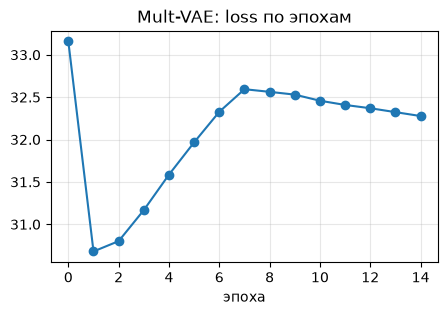

CPU times: user 5min 28s, sys: 14.9 s, total: 5min 43s
Wall time: 8min 16s


In [8]:
%%time
my_heuristic_model = SegmentPopular().fit(train_stage_1); timer('heuristic fitted')

# Подбор гиперпараметров iALS по Recall@50 на valid_stage_1 (новые для юзера айтемы, тёплые юзеры)
_seen = build_seen(train_stage_1)
_vpos = valid_stage_1[valid_stage_1.target == 1]
_valid_new = _vpos[[i not in _seen.get(u, ()) for u, i in zip(_vpos.u, _vpos.i)]]
_valid_new = _valid_new[_valid_new.u.isin(list(_seen))].groupby('u')['i'].agg(set)
tune_users = _valid_new.index.values
tune_users = np.random.default_rng(SEED).choice(tune_users, min(8000, len(tune_users)), replace=False)
als_tuning = []
for factors in [4, 8, 16, 32, 64]:
    for alpha in [10, 40, 100]:
        m = ALSRecommender(factors=factors, alpha=alpha).fit(train_stage_1)
        recs = m.recommend(tune_users, 50)
        als_tuning.append({'factors': factors, 'alpha': alpha,
                           'recall@50': np.mean([len(set(r) & _valid_new[u]) / len(_valid_new[u]) for r, u in zip(recs, tune_users)])})
als_tuning = pd.DataFrame(als_tuning).sort_values('recall@50', ascending=False)
display(als_tuning)
ALS_PARAMS = dict(factors=int(als_tuning.iloc[0].factors), alpha=float(als_tuning.iloc[0].alpha))
print('ALS_PARAMS =', ALS_PARAMS)
my_matrix_factorization = ALSRecommender(**ALS_PARAMS).fit(train_stage_1); timer('ALS fitted')
my_neural_network = MultVAERecommender(epochs=5 if QUICK else 15).fit(train_stage_1); timer('Mult-VAE fitted')

plt.figure(figsize=(5, 3)); plt.plot(my_neural_network.history, marker='o')
plt.title('Mult-VAE: loss по эпохам'); plt.xlabel('эпоха'); plt.grid(alpha=0.3); plt.show()
stage1_models = [my_heuristic_model, my_matrix_factorization, my_neural_network]

Каждая модель должна уметь:
1) для пары user_item предсказывать скор релевантности (масштаб скора не важен), важно обработать случаи, когда модель не можеn проскорить пользователя или айтем, вместо этого вернуть какое-то дефолтное значение
2) для всех пользователей вернуть top-k самых релевантных айтемов (тут вам скоры не нужны)


Дополнительно можно провести анализ кандидат генератов, измерить насколько различные айтемы они рекомендуют, например с помощью таких метрик как: [Ranked based overlap](https://github.com/changyaochen/rbo) или различные вариации [Diversity](https://github.com/MaurizioFD/RecSys2019_DeepLearning_Evaluation/blob/master/Base/Evaluation/metrics.py#L289). **(1 балл)**

In [9]:
# Качество кандидатов на valid_stage_1: Recall@N (доля новых для юзера позитивов периода — target = 1 — попавших в N кандидатов) и MAP@10.
seen_stage1 = my_heuristic_model.seen
valid_pos = valid_stage_1[valid_stage_1.target == 1]   # релевантное = досмотрено больше чем на 50% (target)
valid_gt = valid_pos[[i not in seen_stage1.get(u, ()) for u, i in zip(valid_pos.u, valid_pos.i)]]
valid_gt = valid_gt.groupby('u')['i'].agg(set)
eval_users = valid_gt.index.values
if len(eval_users) > 40000:
    eval_users = np.random.default_rng(SEED).choice(eval_users, 40000, replace=False)
warm_mask = my_matrix_factorization.known_users[eval_users]

def recall_at(recs, gt_sets, k):
    return np.mean([len(set(r[:k]) & g) / len(g) for r, g in zip(recs, gt_sets)])

def map_at(recs, gt_sets, k=10):
    res = []
    for r, g in zip(recs, gt_sets):
        hits = np.isin(r[:k], list(g)).astype(float)
        res.append((hits * np.cumsum(hits) / np.arange(1, k + 1)).sum() / min(k, len(g)))
    return np.mean(res)

MAX_N = 200
cand_recs = {m.name: m.recommend(eval_users, MAX_N) for m in stage1_models}
gts = [valid_gt[u] for u in eval_users]
rows = []
for name, recs in cand_recs.items():
    for N in [10, 20, 50, 100, 200]:
        rows.append({'model': name, 'N': N, 'recall_all': recall_at(recs, gts, N),
                     'recall_warm': recall_at(recs[warm_mask], [g for g, w in zip(gts, warm_mask) if w], N),
                     'recall_cold': recall_at(recs[~warm_mask], [g for g, w in zip(gts, warm_mask) if not w], N) if (~warm_mask).any() else np.nan})
cand_quality = pd.DataFrame(rows).pivot(index='N', columns='model')
print('MAP@10 (все юзеры valid):', {name: round(map_at(recs, gts), 4) for name, recs in cand_recs.items()})
cand_quality.round(4)

MAP@10 (все юзеры valid): {'pop': np.float64(0.1533), 'als': np.float64(0.1354), 'vae': np.float64(0.1597)}


recall_all                 recall_warm                 recall_cold  \
model        als     pop     vae         als     pop     vae         als   
N                                                                          
10        0.2587  0.2787  0.2956      0.1839  0.2124  0.2349      0.4530   
20        0.3062  0.3267  0.3470      0.2396  0.2594  0.2939      0.4789   
50        0.3873  0.3944  0.4328      0.3297  0.3305  0.3907      0.5370   
100       0.4604  0.4627  0.5127      0.4127  0.4034  0.4810      0.5843   
200       0.5482  0.5578  0.6060      0.5057  0.5052  0.5821      0.6587   

                       
model     pop     vae  
N                      
10     0.4508  0.4530  
20     0.5011  0.4846  
50     0.5603  0.5419  
100    0.6165  0.5949  
200    0.6945  0.6678

In [10]:
# Объединение кандидатов: сколько всего уникальных кандидатов и какой recall у объединения
def merge_candidates(rec_dict, n_per_model):
    merged = []
    for r in range(len(next(iter(rec_dict.values())))):
        seen_c, lst = set(), []
        for name, n in n_per_model.items():
            for i in rec_dict[name][r][:n]:
                if i >= 0 and i not in seen_c:
                    seen_c.add(i); lst.append(i)
        merged.append(lst)
    return merged

configs = {'по 20': dict(pop=20, als=20, vae=20), 'по 50': dict(pop=50, als=50, vae=50),
           'pop30+als70+vae70': dict(pop=30, als=70, vae=70), 'по 100': dict(pop=100, als=100, vae=100)}
rows = []
for cname, cfg in configs.items():
    merged = merge_candidates(cand_recs, cfg)
    rows.append({'config': cname, 'avg_candidates': np.mean([len(m) for m in merged]),
                 'recall_union': np.mean([len(set(m) & g) / len(g) for m, g in zip(merged, gts)])})
pd.DataFrame(rows)

,config,avg_candidates,recall_union
0,по 20,36.873000,0.409543
1,по 50,94.706900,0.510721
2,pop30+als70+vae70,106.251025,0.524883
3,по 100,188.137925,0.598580


**Выводы по генераторам кандидатов.** Оценка на valid_stage_1 (последние 7 дней трейна); релевантное — новые для юзера айтемы с `target = 1`.
* **Лучший генератор — Mult-VAE.**
  * По всем юзерам: Recall@50 = 0.433 и MAP@10 = 0.160. У эвристики — 0.394 и 0.153, у iALS — 0.387 и 0.135.
  * По тёплым юзерам: Recall@50 = 0.391 у VAE, 0.331 у эвристики и 0.330 у iALS.
* **У iALS лучшие параметры на валидации — всего 8 факторов** и alpha = 40. Спрос в KION сильно сконцентрирован, и малоранговая модель почти повторяет популярность. С 64 факторами Recall@50 падает до 0.19–0.26.
* **Холодных юзеров iALS не знает**, им отдаётся популярное из трейна. Сегментная эвристика для них немного лучше: Recall@50 = 0.560 против 0.537 у iALS и 0.542 у VAE при z = 0.
* **Объединение** «pop 30 + als 70 + vae 70» даёт в среднем 106 кандидатов и Recall = 0.525. Лучшая одиночная модель при сопоставимом числе кандидатов (VAE, N = 100) даёт 0.513, то есть прибавка от объединения небольшая, около +0.01. Основная польза объединения — в другом: разные генераторы дополняют друг друга для холодных и тёплых юзеров, а ранкер получает скоры всех трёх моделей как признаки.
* **Вариант «по 100»** поднимает recall до 0.599, но почти удваивает число строк (188 на юзера). Для бустинга на миллионе юзеров выбран вариант с ~106 кандидатами.

#### Анализ генераторов кандидатов: насколько разные списки они выдают
* **RBO** (rank-biased overlap, p = 0.9) — похожесть двух ранжированных списков с бо́льшим весом верхних позиций;
* **Jaccard@20** — пересечение множеств топ-20;
* **Coverage** — доля каталога, попадающая хоть кому-то в топ-20;
* **ILD@20** (intra-list diversity) — среднее попарное жанровое расстояние (1 − Jaccard по жанрам) внутри списка;
* **Novelty@20** — средняя «непопулярность» рекомендованного: −log2 доли юзеров, смотревших айтем.

In [11]:
def rbo_ext(S, T, p=0.9):
    """Rank-biased overlap (Webber et al., 2010), экстраполированная версия для списков одинаковой длины k:
    RBO_ext = X_k / k * p^k + (1 - p) / p * sum_{d=1..k} (X_d / d) * p^d, где X_d — размер пересечения топ-d."""
    S, T = list(S), list(T)
    k = min(len(S), len(T))
    seen_s, seen_t, overlap, acc = set(), set(), 0, 0.0
    for d in range(1, k + 1):
        a, b = S[d - 1], T[d - 1]
        if a == b:
            overlap += 1
        else:
            overlap += (a in seen_t) + (b in seen_s)
        seen_s.add(a); seen_t.add(b)
        acc += overlap / d * p ** d
    return overlap / k * p ** k + (1 - p) / p * acc

assert abs(rbo_ext([1, 2, 3], [1, 2, 3]) - 1) < 1e-9 and rbo_ext([1, 2, 3], [4, 5, 6]) == 0

# жанры айтемов: sparse-матрица айтем × жанр
items_idx = items.assign(i=iid2idx.loc[items.item_id].values)
genre_lists = items_idx.genres.fillna('').str.lower().str.split(r',\s*')
all_genres = sorted({g for gl in genre_lists for g in gl if g})
genre2col = {g: c for c, g in enumerate(all_genres)}
gi, gj = [], []
for i, gl in zip(items_idx.i.values, genre_lists):
    for g in gl:
        if g:
            gi.append(i); gj.append(genre2col[g])
ITEM_GENRES = sps.csr_matrix((np.ones(len(gi), dtype=np.float32), (gi, gj)), shape=(N_ITEMS, len(all_genres)))
ITEM_GENRES.data[:] = 1.0
GENRE_COUNT = np.asarray(ITEM_GENRES.sum(axis=1)).ravel()

def ild(lst):
    lst = [i for i in lst if i >= 0]
    if len(lst) < 2:
        return np.nan
    G = ITEM_GENRES[lst]
    inter = (G @ G.T).toarray()
    union = GENRE_COUNT[lst][:, None] + GENRE_COUNT[lst][None, :] - inter
    sim = np.divide(inter, union, out=np.zeros_like(inter), where=union > 0)
    iu = np.triu_indices(len(lst), 1)
    return float(1 - sim[iu].mean())

item_user_share = np.bincount(train_stage_1.i, minlength=N_ITEMS) / train_stage_1.u.nunique()
def novelty(lst):
    lst = [i for i in lst if i >= 0]
    return float(np.mean(-np.log2(np.maximum(item_user_share[lst], 1e-7)))) if lst else np.nan

sample = np.random.default_rng(1).choice(np.where(warm_mask)[0], size=min(5000, warm_mask.sum()), replace=False)
names = list(cand_recs)
pair_rows = []
for a in range(len(names)):
    for b in range(a + 1, len(names)):
        A, B = cand_recs[names[a]], cand_recs[names[b]]
        rbos = [rbo_ext(A[r][:50], B[r][:50], p=0.9) for r in sample]
        jac = [len(set(A[r][:20]) & set(B[r][:20])) / len(set(A[r][:20]) | set(B[r][:20])) for r in sample]
        pair_rows.append({'pair': f'{names[a]} vs {names[b]}', 'RBO@50 (p=0.9)': np.mean(rbos), 'Jaccard@20': np.mean(jac)})
single_rows = []
for name in names:
    R = cand_recs[name][sample]
    single_rows.append({'model': name, 'coverage@20': len(set(R[:, :20].ravel()) - {-1}) / N_ITEMS,
                        'ILD@20': np.nanmean([ild(r[:20]) for r in R]), 'novelty@20': np.nanmean([novelty(r[:20]) for r in R]),
                        'recall@50 (warm)': cand_quality.loc[50, ('recall_warm', name)]})
display(pd.DataFrame(pair_rows).round(3))
pd.DataFrame(single_rows).round(4)

,pair,RBO@50 (p=0.9),Jaccard@20
0,pop vs als,0.293,0.219
1,pop vs vae,0.426,0.315
2,als vs vae,0.411,0.331


,model,coverage@20,ILD@20,novelty@20,recall@50 (warm)
0,pop,0.0060,0.8339,4.9832,0.3305
1,als,0.0237,0.7734,5.9376,0.3297
2,vae,0.1408,0.7993,5.7724,0.3907


**Разнообразие генераторов.** Генераторы выдают заметно разные списки:
* **RBO.** Самые непохожие пары — эвристика и iALS: RBO = 0.29. У эвристики и VAE RBO = 0.43, у iALS и VAE — 0.41.
* **Покрытие каталога в топ-20.** У эвристики всего 0.6% — всем почти одно и то же. У iALS — 2.4%, у VAE — 14%.
* **Новизна** выше всего у iALS (5.94): он чаще рекомендует менее популярное.
* **Жанровое разнообразие внутри списка (ILD)**, наоборот, максимально у эвристики (0.83: популярные хиты из разных жанров) и минимально у iALS (0.77: списки ближе к вкусу юзера и потому однороднее).


### 2 Этап. Генерация и сборка признаков. (max 2 балла)
Необходимо собрать минимум 10 осмысленных (`np.radndom.rand()` не подойдет) признаков, при этом:
1. 2 должны относиться только к сущности "пользователь" (например средний % просмотра фильмов у этой возрастной категории)
2. 2 должны относиться только к сущности "айтем" (например средний средний % просмотра данного фильма)
3. 6 признаков, которые показывают связь пользователя и айтема (например средний % просмотра фильмов с данным актером (айтем) у пользователей с таким же полом (пользователь)). 

### ВАЖНО!  

1. **В датасете есть колонка `watched_prct`. Ее можно использовать для генерации признаков (например сколько пользователь в среднем смотрит фильмы), но нельзя подавать в модель, как отдельную фичу, потому что она напрямую связана с target.**
2. **Все признаки должны быть собраны без дата лика, то есть если пользователь посмотрел фильм 10 августа, то признаки мы можем считать только на данных до 9 августа включительно.**


### Разбалловка
Обучение ранкера будет проходить на `valid_stage_1`, как  раз на которой мы валидировали модели, а тестировать на `test`. Поэтому есть 2 варианта сборки признаков, **реализовать нужно только 1 из них:**
1. Для обучения собираем признаки на первый день `valid_stage_1`, а для теста на первый день `test`. Например, если `valid_stage_1` начинается 5 сентября, то все признаки мы можем собирать только по 4 сентября включительно. **(1 балл)**
2. Признаки будем собирать честно на каждый день, то есть на 5 сентября собираем с начала до 4, на 6 сентября с начала до 5 и т.д. **(2 балла)**

### Сборка признаков: «честно» на каждый день (вариант 2)

**Постановка.** Строка выборки — тройка (юзер `u`, день `d`, кандидат `i`): юзер был активен в день `d`, `i` — кандидат от моделей первого уровня (кроме того, что юзер уже смотрел до дня `d`). Таргет — `target` из данных за день `d`: юзер `u` досмотрел айтем `i` больше чем на 50% (в данных `target` ровно равен `watched_pct > 50`). Это ровно задача «рекомендации на завтра» из этапа 4.

**Без утечки.** Для строк дня `d` все признаки считаются только по интеракциям с `day < d`: функция `build_features` перебирает дни и для каждого заново агрегирует историю до этого дня. Скоры моделей первого уровня берутся из моделей, обученных до начала периода (для `valid_stage_1` — на `train_stage_1`, для `test` — на всём `train`). `watched_pct` используется только в агрегатах по прошлому.

| группа | признаки |
|---|---|
| пользователь | `u_n_views`, `u_n_views_7d`, `u_mean_pct`, `u_days_since_last`, `u_series_share`, `age`, `income`, `sex`, `kids_flg` |
| айтем | `i_n_views`, `i_n_views_7d`, `i_trend`, `i_mean_pct`, `i_days_on_platform`, `content_type`, `release_year`, `for_kids`, `age_rating` |
| пользователь × айтем | `ui_genre_affinity` (доля жанров айтема в истории юзера), `ui_genre_pct` (средний % досмотра юзером айтемов этих жанров), `ui_type_share` (доля типа контента айтема в истории юзера), `ui_age_pop` и `ui_sex_pop` (популярность айтема среди юзеров того же возраста / пола за 14 дней), `ui_age_pct` (средний % досмотра айтема в возрастной группе юзера), `ui_director_seen` (сколько фильмов этого режиссёра юзер уже смотрел), `ui_country_share` (доля стран айтема в истории юзера), `ui_year_diff` (|год выпуска − средний год у юзера|) |
| модели 1-го уровня | `score_pop`, `score_als`, `score_vae`, `rank_pop`, `rank_als`, `rank_vae` (позиция в списке генератора, NaN если айтем не из него), `n_generators` |

In [12]:
# Статические таблицы для признаков
items_static = pd.DataFrame({'i': np.arange(N_ITEMS)})
items_static = items_static.merge(items_idx[['i', 'content_type', 'release_year', 'for_kids', 'age_rating', 'countries', 'directors']], on='i', how='left')
ITEM_IS_SERIES = (items_static.content_type == 'series').values
ITEM_YEAR = items_static.release_year.values.astype(float)

def multi_hot(series, min_count=1):
    lists = series.fillna('').str.lower().str.split(r',\s*')
    vocab = pd.Series([v for l in lists for v in l if v]).value_counts()
    vocab = {v: c for c, v in enumerate(vocab.index[vocab >= min_count])}
    r, c = [], []
    for i, l in enumerate(lists):
        for v in l:
            if v in vocab:
                r.append(i); c.append(vocab[v])
    m = sps.csr_matrix((np.ones(len(r), dtype=np.float32), (r, c)), shape=(len(series), len(vocab)))
    m.data[:] = 1.0
    return m

ITEM_COUNTRIES = multi_hot(items_static.countries)
ITEM_DIRECTORS = multi_hot(items_static.directors)

users_static = pd.DataFrame({'u': np.arange(N_USERS)}).merge(users_idx[['u', 'age', 'income', 'sex', 'kids_flg']], on='u', how='left')
for c in ['age', 'income', 'sex']:
    users_static[c] = users_static[c].fillna('unknown')
AGE_CODE = pd.factorize(users_static.age)[0]
SEX_CODE = pd.factorize(users_static.sex)[0]
CAT_FEATURES = ['age', 'income', 'sex', 'content_type', 'age_rating']


def rowdot(A, B, rows_a, rows_b):
    """Построчное скалярное произведение A[rows_a] и B[rows_b] для sparse-матриц."""
    return np.asarray(A[rows_a].multiply(B[rows_b]).sum(axis=1)).ravel()


def day_context(hist, d):
    """Агрегаты истории, нужные для признаков дня d (hist содержит только day < d). Считаются один раз на день."""
    c = {'d': d}
    pct = hist.watched_pct.clip(0, 100).fillna(0).values
    hu, hi, hd = hist.u.values, hist.i.values, hist.day.values
    c['cnt_u'] = np.bincount(hu, minlength=N_USERS)
    c['cnt_u7'] = np.bincount(hu[hd >= d - 7], minlength=N_USERS)
    c['sum_pct_u'] = np.bincount(hu, weights=pct, minlength=N_USERS)
    c['last_u'] = np.full(N_USERS, -10_000); np.maximum.at(c['last_u'], hu, hd)
    c['ser_u'] = np.bincount(hu, weights=ITEM_IS_SERIES[hi].astype(float), minlength=N_USERS)
    c['cnt_i'] = np.bincount(hi, minlength=N_ITEMS)
    c['cnt_i7'] = np.bincount(hi[hd >= d - 7], minlength=N_ITEMS)
    c['cnt_i_prev7'] = np.bincount(hi[(hd >= d - 14) & (hd < d - 7)], minlength=N_ITEMS)
    c['sum_pct_i'] = np.bincount(hi, weights=pct, minlength=N_ITEMS)
    c['first_i'] = np.full(N_ITEMS, 10_000); np.minimum.at(c['first_i'], hi, hd)
    H = sps.csr_matrix((np.ones(len(hist), dtype=np.float32), (hu, hi)), shape=(N_USERS, N_ITEMS))
    Hp = sps.csr_matrix((pct.astype(np.float32), (hu, hi)), shape=(N_USERS, N_ITEMS))
    c['UG'] = (H @ ITEM_GENRES).tocsr()             # число просмотров юзера по жанрам
    c['UGp'] = (Hp @ ITEM_GENRES).tocsr()           # сумма % досмотра по жанрам
    c['UD'] = (H @ ITEM_DIRECTORS).tocsr()          # просмотры по режиссёрам
    c['UC'] = (H @ ITEM_COUNTRIES).tocsr()          # просмотры по странам
    del H, Hp
    m14 = hd >= d - 14
    for code, name in [(AGE_CODE, 'age'), (SEX_CODE, 'sex')]:
        n_seg = code.max() + 1
        seg_item = sps.csr_matrix((np.ones(m14.sum()), (code[hu[m14]], hi[m14])), shape=(n_seg, N_ITEMS)).toarray()
        c[f'seg_{name}'] = seg_item
        c[f'seg_{name}_tot'] = seg_item.sum(axis=1)
        if name == 'age':
            c['seg_age_pct'] = sps.csr_matrix((pct[m14], (code[hu[m14]], hi[m14])), shape=(n_seg, N_ITEMS)).toarray()
    year_valid = ~np.isnan(ITEM_YEAR[hi])
    sum_year = np.bincount(hu[year_valid], weights=ITEM_YEAR[hi][year_valid], minlength=N_USERS)
    cnt_year = np.bincount(hu[year_valid], minlength=N_USERS)
    c['mean_year'] = np.divide(sum_year, cnt_year, out=np.full(N_USERS, np.nan), where=cnt_year > 0)
    return c


ITEM_N_COUNTRIES = None

def day_features(rows, c):
    """Признаки для строк одного дня по контексту c = day_context(история до этого дня)."""
    global ITEM_N_COUNTRIES
    if ITEM_N_COUNTRIES is None:
        ITEM_N_COUNTRIES = np.maximum(np.asarray(ITEM_COUNTRIES.sum(axis=1)).ravel(), 1)
    u, i, d = rows.u.values, rows.i.values, c['d']
    cu = c['cnt_u'][u]
    has = cu > 0
    nan = lambda: np.full(len(u), np.nan)
    f = {}
    # --- пользователь
    f['u_n_views'] = cu
    f['u_n_views_7d'] = c['cnt_u7'][u]
    f['u_mean_pct'] = np.divide(c['sum_pct_u'][u], cu, out=nan(), where=has)
    f['u_days_since_last'] = np.where(has, d - c['last_u'][u], np.nan)
    f['u_series_share'] = np.divide(c['ser_u'][u], cu, out=nan(), where=has)
    # --- айтем
    ci = c['cnt_i'][i]
    f['i_n_views'] = ci
    f['i_n_views_7d'] = c['cnt_i7'][i]
    f['i_trend'] = (c['cnt_i7'][i] + 1) / (c['cnt_i_prev7'][i] + 1)
    f['i_mean_pct'] = np.divide(c['sum_pct_i'][i], ci, out=np.full(len(i), np.nan), where=ci > 0)
    f['i_days_on_platform'] = np.where(ci > 0, d - c['first_i'][i], -1)
    # --- пользователь × айтем
    ug_dot = rowdot(c['UG'], ITEM_GENRES, u, i)
    f['ui_genre_affinity'] = np.divide(ug_dot, cu * np.maximum(GENRE_COUNT[i], 1), out=nan(), where=has)
    f['ui_genre_pct'] = np.divide(rowdot(c['UGp'], ITEM_GENRES, u, i), ug_dot, out=nan(), where=ug_dot > 0)
    f['ui_type_share'] = np.where(ITEM_IS_SERIES[i], f['u_series_share'], 1 - f['u_series_share'])
    for code, name in [(AGE_CODE, 'age'), (SEX_CODE, 'sex')]:
        seg_cnt = c[f'seg_{name}'][code[u], i]
        f[f'ui_{name}_pop'] = seg_cnt / np.maximum(c[f'seg_{name}_tot'][code[u]], 1)
        if name == 'age':
            f['ui_age_pct'] = np.divide(c['seg_age_pct'][code[u], i], seg_cnt, out=nan(), where=seg_cnt > 0)
    f['ui_director_seen'] = rowdot(c['UD'], ITEM_DIRECTORS, u, i)
    f['ui_country_share'] = np.divide(rowdot(c['UC'], ITEM_COUNTRIES, u, i), cu * ITEM_N_COUNTRIES[i], out=nan(), where=has)
    f['ui_year_diff'] = np.abs(ITEM_YEAR[i] - c['mean_year'][u])
    return pd.DataFrame(f, index=rows.index).astype(np.float32)


def build_features(rows, hist_all, ctx=None):
    """rows: DataFrame[u, i, day, ...]. Для каждого дня d признаки считаются только по hist_all[day < d].
    ctx — заранее посчитанный day_context (для инференса на один день чанками)."""
    parts = []
    for d, rows_d in rows.groupby('day'):
        c = ctx if (ctx is not None and ctx['d'] == d) else day_context(hist_all[hist_all.day < d], d)
        parts.append(day_features(rows_d, c))
    feats = pd.concat(parts).loc[rows.index]
    out = pd.concat([rows, feats], axis=1)
    out = out.merge(users_static, on='u', how='left').merge(
        items_static[['i', 'content_type', 'release_year', 'for_kids', 'age_rating']], on='i', how='left')
    for c in ['content_type', 'age_rating']:
        out[c] = out[c].astype(str)
    return out

In [13]:
N_PER_MODEL = dict(pop=30, als=70, vae=70)     # выбрано по таблице recall объединения выше

def make_candidate_rows(user_days, models, hist_for_seen, n_per_model=N_PER_MODEL, period=None, only_positive_groups=False):
    """user_days: DataFrame[u, day]. Кандидаты от всех моделей (без дублей), скоры всех моделей и ранги.
    Из кандидатов убираем то, что юзер смотрел до дня d (по hist_for_seen).
    period — интеракции периода для таргета; only_positive_groups — оставить группы (u, day) хотя бы с одним позитивом."""
    uniq_u = user_days.u.unique()
    recs = {m.name: m.recommend(uniq_u, max(n_per_model.values())) for m in models}
    pos = {u: r for r, u in enumerate(uniq_u)}
    rows_u, rows_i, ranks = [], [], {m.name: [] for m in models}
    for u in uniq_u:
        r = pos[u]; seen_c = {}
        for m in models:
            for rank, it in enumerate(recs[m.name][r][:n_per_model[m.name]]):
                if it >= 0 and it not in seen_c:
                    seen_c[it] = {}
                if it >= 0:
                    seen_c[it][m.name] = rank + 1
        for it, rk in seen_c.items():
            rows_u.append(u); rows_i.append(it)
            for m in models:
                ranks[m.name].append(rk.get(m.name, np.nan))
    cand = pd.DataFrame({'u': np.array(rows_u, dtype=np.int32), 'i': np.array(rows_i, dtype=np.int32)})
    for m in models:
        cand[f'rank_{m.name}'] = np.array(ranks[m.name], dtype=np.float32)
    cand['n_generators'] = cand[[f'rank_{m.name}' for m in models]].notna().sum(axis=1)
    rows = user_days[['u', 'day']].merge(cand, on='u')
    # не рекомендуем то, что юзер уже смотрел до дня d
    first_seen = hist_for_seen if 'first_seen_day' in hist_for_seen.columns else first_seen_table(hist_for_seen)
    rows = rows.merge(first_seen[first_seen.u.isin(uniq_u)], on=['u', 'i'], how='left')
    rows = rows[~(rows.first_seen_day < rows.day)].drop(columns='first_seen_day').reset_index(drop=True)
    if period is not None:
        rows = add_target(rows, period)
        if only_positive_groups:
            rows = rows[rows.groupby(['u', 'day']).target.transform('max') == 1].reset_index(drop=True)
    for m in models:
        rows[f'score_{m.name}'] = m.score(rows.u.values, rows.i.values).astype(np.float32)
    return rows


def first_seen_table(hist):
    return hist.groupby(['u', 'i']).day.min().rename('first_seen_day').reset_index()


def add_target(rows, period):
    pos = period[period.target == 1][['u', 'i', 'day']].drop_duplicates().assign(target=1)   # позитив — target из данных
    rows = rows.merge(pos, on=['u', 'i', 'day'], how='left')
    rows['target'] = rows.target.fillna(0).astype(np.int8)
    return rows


# --- обучающая выборка ранкера: дни valid_stage_1, модели обучены на train_stage_1
rng = np.random.default_rng(SEED)
valid_user_days = valid_stage_1[['u', 'day']].drop_duplicates()
MAX_TRAIN_USER_DAYS = 15000 if QUICK else 80000
if len(valid_user_days) > MAX_TRAIN_USER_DAYS:
    valid_user_days = valid_user_days.sample(MAX_TRAIN_USER_DAYS, random_state=SEED)
timer(f'user-days for ranker train: {len(valid_user_days)}')
# hist для фильтра просмотренного: весь train (фильтруется только то, что юзер смотрел ДО дня d).
# Оставляем группы (юзер, день), где среди кандидатов есть хотя бы один позитив — иначе группа ничего не даёт ранкеру.
train_rows = make_candidate_rows(valid_user_days, stage1_models, train, period=valid_stage_1, only_positive_groups=True)
print(f'групп с позитивом среди кандидатов: {train_rows.groupby(["u", "day"]).ngroups} из {len(valid_user_days)}')
timer(f'candidates: {len(train_rows)} строк, positives: {train_rows.target.sum()}')

train_df_with_features = build_features(train_rows, train)
timer(f'train features: {train_df_with_features.shape}')
train_df_with_features.head()

[  516.0s] user-days for ranker train: 80000


групп с позитивом среди кандидатов: 18792 из 80000
[  531.2s] candidates: 1993847 строк, positives: 21125


[  540.9s] train features: (1993847, 38)


,u,day,i,rank_pop,rank_als,rank_vae,n_generators,target,score_pop,score_als,...,ui_country_share,ui_year_diff,age,income,sex,kids_flg,content_type,release_year,for_kids,age_rating
0,265432,152,9393,1.0,4.0,4.0,3,1,0.044800,0.0,...,NaN,NaN,age_25_34,income_20_40,М,0.0,film,2021.0,NaN,18.0
1,265432,152,10072,2.0,1.0,1.0,3,0,0.026524,0.0,...,NaN,NaN,age_25_34,income_20_40,М,0.0,series,2021.0,NaN,18.0
2,265432,152,14769,3.0,2.0,2.0,3,0,0.018659,0.0,...,NaN,NaN,age_25_34,income_20_40,М,0.0,series,2021.0,NaN,18.0
3,265432,152,13387,4.0,3.0,3.0,3,0,0.018324,0.0,...,NaN,NaN,age_25_34,income_20_40,М,0.0,film,2021.0,NaN,12.0
4,265432,152,3599,5.0,6.0,6.0,3,0,0.017071,0.0,...,NaN,NaN,age_25_34,income_20_40,М,0.0,film,2021.0,NaN,16.0


In [14]:
%%time
# --- тест: модели первого уровня переобучаем на всём train (то есть на данных до теста)
heur_full = SegmentPopular().fit(train)
als_full = ALSRecommender(**ALS_PARAMS).fit(train)
vae_full = MultVAERecommender(epochs=5 if QUICK else 15).fit(train)
stage1_full = [heur_full, als_full, vae_full]
timer('stage-1 models refitted on full train')

hist_test = pd.concat([train, test], ignore_index=True)   # для признаков дня d берётся только day < d
test_user_days = test[['u', 'day']].drop_duplicates()
MAX_TEST_USER_DAYS = 15000 if QUICK else 40000
if len(test_user_days) > MAX_TEST_USER_DAYS:
    test_user_days = test_user_days.sample(MAX_TEST_USER_DAYS, random_state=SEED + 1)
test_rows = make_candidate_rows(test_user_days, stage1_full, hist_test, period=test)
test_df_with_features = build_features(test_rows, hist_test)
test_df_with_features['is_cold'] = ~als_full.known_users[test_df_with_features.u.values]
timer(f'test features: {test_df_with_features.shape}, positives {test_df_with_features.target.sum()}')

[  785.9s] stage-1 models refitted on full train


[  811.6s] test features: (4211423, 39), positives 10316


CPU times: user 1min 25s, sys: 15.9 s, total: 1min 41s
Wall time: 4min 30s



### 3 Этап. Обучение финального ранкера (max 2 балла)
Собрав все признаки из этапа 2, добавив скоры моделей из этапа 1 для каждой пары пользователь-айтем (где это возможно), пришло время обучать ранкер. В качестве ранкера можно использовать либо [xgboost](https://xgboost.readthedocs.io/en/stable/) или [catboost](https://catboost.ai/). Обучать можно как `Classfier`, так и `Ranker`, выбираем то, что лучше сработает. Обучение ранкера будет проходить на `valid_stage_1`, как  раз на которой мы валидировали модели, а тестировать на `test`, которую мы до сих пор не трогали.  Заметьте, что у нас в тесте есть холодные пользователи – те, кого не было в train и активные – те, кто был в train. Возможно их стоит обработать по отдельности (а может и нет).  
(1 балл)

После получения лучшей модели надо посмотреть на важность признаков и [shap values](https://shap.readthedocs.io/en/latest/index.html), чтобы:
1. Интерпритировать признаки, которые вы собрали, насколько они полезные
2. Проверить наличие ликов – если важность фичи в 100 раз больше, чем у всех остальных, то явно что-то не то  

(1 балл)






In [15]:
from catboost import CatBoostRanker, CatBoostClassifier, Pool

FEATURES = [c for c in train_df_with_features.columns if c not in ('u', 'i', 'day', 'target', 'is_cold')]
print(len(FEATURES), 'признаков:', FEATURES)

# валидация для early stopping — 15% юзеров обучающей выборки ранкера
tr = train_df_with_features.sort_values(['u', 'day']).reset_index(drop=True)
tr['group'] = tr.groupby(['u', 'day']).ngroup()
val_users = pd.Series(tr.u.unique()).sample(frac=0.15, random_state=SEED)
is_val = tr.u.isin(val_users)
def pool(d):
    return Pool(d[FEATURES], label=d.target, group_id=d.group, cat_features=CAT_FEATURES)
train_pool, val_pool = pool(tr[~is_val]), pool(tr[is_val])

ranker = CatBoostRanker(loss_function='YetiRank', eval_metric='NDCG:top=10', iterations=300 if QUICK else 1500,
                        learning_rate=0.05, depth=6, random_seed=SEED, early_stopping_rounds=100, verbose=100,
                        thread_count=-1, train_dir=os.path.join('logs', 'catboost_info'))
ranker.fit(train_pool, eval_set=val_pool)

clf = CatBoostClassifier(loss_function='Logloss', iterations=300 if QUICK else 1500, learning_rate=0.05, depth=6,
                         random_seed=SEED, early_stopping_rounds=100, verbose=100, thread_count=-1,
                         train_dir=os.path.join('logs', 'catboost_info'))
clf.fit(Pool(tr[~is_val][FEATURES], tr[~is_val].target, cat_features=CAT_FEATURES),
        eval_set=Pool(tr[is_val][FEATURES], tr[is_val].target, cat_features=CAT_FEATURES))

34 признаков: ['rank_pop', 'rank_als', 'rank_vae', 'n_generators', 'score_pop', 'score_als', 'score_vae', 'u_n_views', 'u_n_views_7d', 'u_mean_pct', 'u_days_since_last', 'u_series_share', 'i_n_views', 'i_n_views_7d', 'i_trend', 'i_mean_pct', 'i_days_on_platform', 'ui_genre_affinity', 'ui_genre_pct', 'ui_type_share', 'ui_age_pop', 'ui_age_pct', 'ui_sex_pop', 'ui_director_seen', 'ui_country_share', 'ui_year_diff', 'age', 'income', 'sex', 'kids_flg', 'content_type', 'release_year', 'for_kids', 'age_rating']


Groupwise loss function. OneHotMaxSize set to 10


0:	test: 0.2024210	best: 0.2024210 (0)	total: 304ms	remaining: 7m 35s


100:	test: 0.3517331	best: 0.3517331 (100)	total: 21.1s	remaining: 4m 51s


200:	test: 0.3566572	best: 0.3566572 (200)	total: 41.3s	remaining: 4m 26s


...

1000:	learn: 0.0458969	test: 0.0480908	best: 0.0480908 (1000)	total: 3m 14s	remaining: 1m 36s


1100:	learn: 0.0457682	test: 0.0480910	best: 0.0480887 (1022)	total: 3m 33s	remaining: 1m 17s


1200:	learn: 0.0456261	test: 0.0480898	best: 0.0480856 (1178)	total: 3m 52s	remaining: 57.9s


Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.04808564471
bestIteration = 1178

Shrink model to first 1179 iterations.


CatBoostClassifier(depth=6, early_stopping_rounds=100, iterations=1500, learning_rate=0.05, loss_function='Logloss', random_seed=42, train_dir='logs/catboost_info', verbose=100)

In [16]:
def ranking_metrics(df, score_col, k=10, n_rel=None):
    """MAP@k, NDCG@k, Recall@k, HR@k по группам (юзер, день). Релевантные — все новые позитивы (target = 1) этого дня,
    а не только попавшие в кандидаты: n_rel — их число в каждой группе (по умолчанию для теста)."""
    n_rel_series = n_rel_all if n_rel is None else n_rel
    df = df[['u', 'day', 'i', 'target', score_col]].sort_values(['u', 'day', score_col], ascending=[True, True, False])
    df['rank'] = df.groupby(['u', 'day']).cumcount() + 1
    top = df[df['rank'] <= k]
    n_rel = n_rel_series.reindex(pd.MultiIndex.from_frame(top[['u', 'day']].drop_duplicates())).values
    g = top.groupby(['u', 'day'], sort=True)
    hits = top.target.values
    prec_at = g.target.cumsum().values / top['rank'].values
    ap = pd.Series(hits * prec_at, index=top.index).groupby([top.u, top.day]).sum().values / np.minimum(k, n_rel)
    disc = 1 / np.log2(top['rank'].values + 1)
    dcg = pd.Series(hits * disc, index=top.index).groupby([top.u, top.day]).sum().values
    idcg = np.array([(1 / np.log2(np.arange(2, min(k, n) + 2))).sum() for n in n_rel])
    n_hit = g.target.sum().values
    return {f'MAP@{k}': ap.mean(), f'NDCG@{k}': (dcg / idcg).mean(), f'Recall@{k}': (n_hit / n_rel).mean(), f'HR@{k}': (n_hit > 0).mean()}

# ===== Выбор модели и способа обработки холодных — только по валидации =====
# (отложенные 15% юзеров обучающей выборки ранкера, дни valid_stage_1); test до финального отчёта не трогаем
vpos = valid_stage_1[valid_stage_1.target == 1].merge(first_seen_table(train), on=['u', 'i'])
vpos = vpos[vpos.first_seen_day >= vpos.day][['u', 'i', 'day']].drop_duplicates()
n_rel_val = vpos.groupby(['u', 'day']).size()

def add_baseline_preds(d):
    d['pred_pop'] = d['score_pop']
    d['pred_als'] = np.where(d.rank_als.notna(), -d.rank_als, -1e6 - d.rank_pop.fillna(1e3))
    d['pred_vae'] = np.where(d.rank_vae.notna(), -d.rank_vae, -1e6 - d.rank_pop.fillna(1e3))
    d['pred_ranker'] = ranker.predict(d[FEATURES])
    d['pred_clf'] = clf.predict_proba(d[FEATURES])[:, 1]
    return d

MODELS = [('Эвристика (SegmentPopular)', 'pred_pop'), ('iALS', 'pred_als'), ('Mult-VAE', 'pred_vae'),
          ('CatBoostClassifier', 'pred_clf'), ('CatBoostRanker (YetiRank)', 'pred_ranker')]
va = add_baseline_preds(tr[is_val].copy())
val_metrics = pd.DataFrame({name: ranking_metrics(va, col, n_rel=n_rel_val) for name, col in MODELS}).T
display(val_metrics.round(4))
best_name = ('CatBoostRanker (YetiRank)' if val_metrics.loc['CatBoostRanker (YetiRank)', 'NDCG@10'] >=
             val_metrics.loc['CatBoostClassifier', 'NDCG@10'] else 'CatBoostClassifier')
best_model = ranker if best_name.startswith('CatBoostRanker') else clf
def predict_best(d):
    return best_model.predict(d[FEATURES]) if best_model is ranker else best_model.predict_proba(d[FEATURES])[:, 1]
print('Лучшая модель по валидации (NDCG@10):', best_name)

# Отдельный ранкер для «почти холодных» юзеров (меньше 3 просмотров в истории): признаки без CF-скоров.
# Обучаем на train-части выборки ранкера, решение «использовать или нет» — по валидационной части.
COLD_FEATURES = [f for f in FEATURES if not f.startswith(('score_als', 'score_vae', 'rank_als', 'rank_vae'))]
cold_tr = tr[(tr.u_n_views < 3) & ~is_val]
cold_ranker, use_cold_ranker = None, False
if cold_tr.group.nunique() > 300:
    cold_ranker = CatBoostRanker(loss_function='YetiRank', iterations=200 if QUICK else 800, learning_rate=0.05, depth=6,
                                 random_seed=SEED, verbose=0, thread_count=-1, train_dir=os.path.join('logs', 'catboost_info'))
    cold_ranker.fit(Pool(cold_tr[COLD_FEATURES], cold_tr.target, group_id=cold_tr.group, cat_features=CAT_FEATURES))
    cold_va = va[va.u_n_views < 3].copy()
    cold_va['pred_best'] = predict_best(cold_va)
    cold_va['pred_cold'] = cold_ranker.predict(cold_va[COLD_FEATURES])
    cold_val = pd.DataFrame({'общая модель': ranking_metrics(cold_va, 'pred_best', n_rel=n_rel_val),
                             'отдельный ранкер': ranking_metrics(cold_va, 'pred_cold', n_rel=n_rel_val),
                             'эвристика': ranking_metrics(cold_va, 'pred_pop', n_rel=n_rel_val)}).T
    print(f'«почти холодные» на валидации: {cold_va.groupby(["u", "day"]).ngroups} групп')
    display(cold_val.round(4))
    use_cold_ranker = bool(cold_val.loc['отдельный ранкер', 'NDCG@10'] > cold_val.loc['общая модель', 'NDCG@10'])
print('Для холодных юзеров используем отдельный ранкер:', use_cold_ranker)

,MAP@10,NDCG@10,Recall@10,HR@10
Эвристика (SegmentPopular),0.2303,0.2844,0.4357,0.4751
iALS,0.1968,0.2498,0.3963,0.4402
Mult-VAE,0.2407,0.3009,0.4677,0.5139
CatBoostClassifier,0.2772,0.3430,0.5215,0.5776
CatBoostRanker (YetiRank),0.2797,0.3462,0.5269,0.5822


Лучшая модель по валидации (NDCG@10): CatBoostRanker (YetiRank)


«почти холодные» на валидации: 971 групп


,MAP@10,NDCG@10,Recall@10,HR@10
общая модель,0.4105,0.4922,0.7260,0.7631
отдельный ранкер,0.4021,0.4835,0.7159,0.7518
эвристика,0.3840,0.4590,0.6761,0.7085


Для холодных юзеров используем отдельный ранкер: False


In [17]:
# ===== Финальная оценка на test (модели и решения уже выбраны на валидации) =====
# число релевантных в каждой группе теста (новые для юзера позитивы дня d), даже если их нет среди кандидатов
seen_before = hist_test.groupby(['u', 'i']).day.min().rename('first_day').reset_index()
test_pos = test[test.target == 1].merge(seen_before, on=['u', 'i'])
test_pos = test_pos[test_pos.first_day >= test_pos.day][['u', 'i', 'day']].drop_duplicates()
n_rel_all = test_pos.merge(test_user_days, on=['u', 'day']).groupby(['u', 'day']).size()
te = test_df_with_features.merge(n_rel_all.rename('n_rel').reset_index(), on=['u', 'day'])
te = te[te.n_rel > 0].copy()
print('групп (юзер, день) в оценке:', te.groupby(['u', 'day']).ngroups, '| из них холодных юзеров:',
      te[te.is_cold].groupby(['u', 'day']).ngroups)

te = add_baseline_preds(te)
# итоговая система: лучшая модель + (для холодных — отдельный ранкер, если он выиграл на валидации)
te['pred_final'] = predict_best(te).astype(float)
if use_cold_ranker:
    te.loc[te.is_cold, 'pred_final'] = cold_ranker.predict(te.loc[te.is_cold, COLD_FEATURES])
rows = []
for name, col in MODELS + [('Итоговая система', 'pred_final')]:
    for part, mask in [('все', np.ones(len(te), bool)), ('активные', ~te.is_cold.values), ('холодные', te.is_cold.values)]:
        if mask.any():
            rows.append({'модель': name, 'юзеры': part, **ranking_metrics(te[mask], col)})
test_metrics = pd.DataFrame(rows).set_index(['модель', 'юзеры']).unstack('юзеры')
test_metrics.round(4)

групп (юзер, день) в оценке: 17320 | из них холодных юзеров: 4656


MAP@10                   NDCG@10          \
юзеры                      активные     все холодные активные     все   
модель                                                                  
CatBoostClassifier           0.1054  0.1280   0.1894   0.1361  0.1631   
CatBoostRanker (YetiRank)    0.1063  0.1285   0.1892   0.1370  0.1636   
Mult-VAE                     0.0944  0.1114   0.1579   0.1208  0.1437   
iALS                         0.0686  0.0962   0.1712   0.0896  0.1237   
Итоговая система             0.1063  0.1285   0.1892   0.1370  0.1636   
Эвристика (SegmentPopular)   0.0804  0.1088   0.1863   0.1024  0.1362   

                                    Recall@10                     HR@10  \
юзеры                      холодные  активные     все холодные активные   
модель                                                                    
CatBoostClassifier           0.2364    0.2189  0.2588   0.3673   0.2491   
CatBoostRanker (YetiRank)    0.2360    0.2200  0.2593   0.3663   0.2506   
Mult-VAE                     0.2060    0.1919  0.2326   0.3432   0.2179   
iALS                         0.2162    0.1469  0.1996   0.3429   0.1688   
Итоговая система             0.2360    0.2200  0.2593   0.3663   0.2506   
Эвристика (SegmentPopular)   0.2282    0.1630  0.2126   0.3476   0.1812   

                                             
юзеры                          все холодные  
модель                                       
CatBoostClassifier          0.2882   0.3945  
CatBoostRanker (YetiRank)   0.2893   0.3945  
Mult-VAE                    0.2584   0.3686  
iALS                        0.2224   0.3681  
Итоговая система            0.2893   0.3945  
Эвристика (SegmentPopular)  0.2328   0.3731

**Выводы по ранкеру.**
* **Как выбирали.** Модель и способ обработки холодных выбраны по валидации — отложенным 15% юзеров valid_stage_1, ячейка выше. CatBoostRanker (YetiRank) там лучше классификатора: NDCG@10 = 0.346 против 0.343. Метрики на валидации выше тестовых, потому что в выборку ранкера попали только группы «юзер × день», где среди кандидатов есть хотя бы один позитив.
* **Тест — 17 320 групп «юзер × день».** Признаки для каждой группы посчитаны только по данным до этого дня. Двухуровневая модель лучше любого одиночного генератора: у итоговой системы **NDCG@10 = 0.1636**, MAP@10 = 0.1285, Recall@10 = 0.259. У лучшего одиночного Mult-VAE — 0.1437, 0.1114 и 0.233, у эвристики — 0.1362, 0.1088 и 0.213. Прирост NDCG@10 к лучшему генератору — около +14%.
* **Ранкер и классификатор на тесте почти равны** (NDCG@10 0.1636 против 0.1631), то есть выбор по валидации подтвердился.
* **Активные юзеры:** NDCG@10 вырос с 0.121 (VAE) до 0.137.
* **Холодные юзеры:** общая модель даёт 0.236 против 0.228 у эвристики. Метрики у холодных выше, чем у активных: новые юзеры в первые дни смотрят в основном главные новинки, их проще угадать.

In [18]:
# Для справки: холодные юзеры теста — общая модель, отдельный ранкер и эвристика (решение принималось на валидации)
cold_te = te[te.is_cold].copy()
cold_te['pred_best'] = predict_best(cold_te)
cmp = {'общая модель': ranking_metrics(cold_te, 'pred_best'), 'эвристика': ranking_metrics(cold_te, 'pred_pop')}
if cold_ranker is not None:
    cold_te['pred_cold'] = cold_ranker.predict(cold_te[COLD_FEATURES])
    cmp['отдельный ранкер для холодных'] = ranking_metrics(cold_te, 'pred_cold')
pd.DataFrame(cmp).T.round(4)

,MAP@10,NDCG@10,Recall@10,HR@10
общая модель,0.1892,0.2360,0.3663,0.3945
эвристика,0.1863,0.2282,0.3476,0.3731
отдельный ранкер для холодных,0.1978,0.2433,0.3694,0.3976


**Отдельная обработка холодных юзеров.**
* **На валидации отдельный ранкер проиграл общей модели.** Ранкер обучен на признаках без CF-скоров, на юзерах с историей меньше 3 просмотров, и на 971 таком отложенном случае получил NDCG@10 0.484 против 0.492 у общей модели. Поэтому в итоговой системе и в инференсе холодные юзеры идут через общую модель.
* **На тесте (таблица ниже, только для справки) отдельный ранкер оказался бы немного лучше:** 0.243 против 0.236. Расхождение объяснимо. На валидации «холодными» считаются юзеры с короткой историей, а в тесте — юзеры, которых вообще нет в трейне. К тому же выборки небольшие (≈1–5 тыс. групп), и разница в пределах шума. Решение принимаем по валидации, чтобы не подгонять систему под тест.

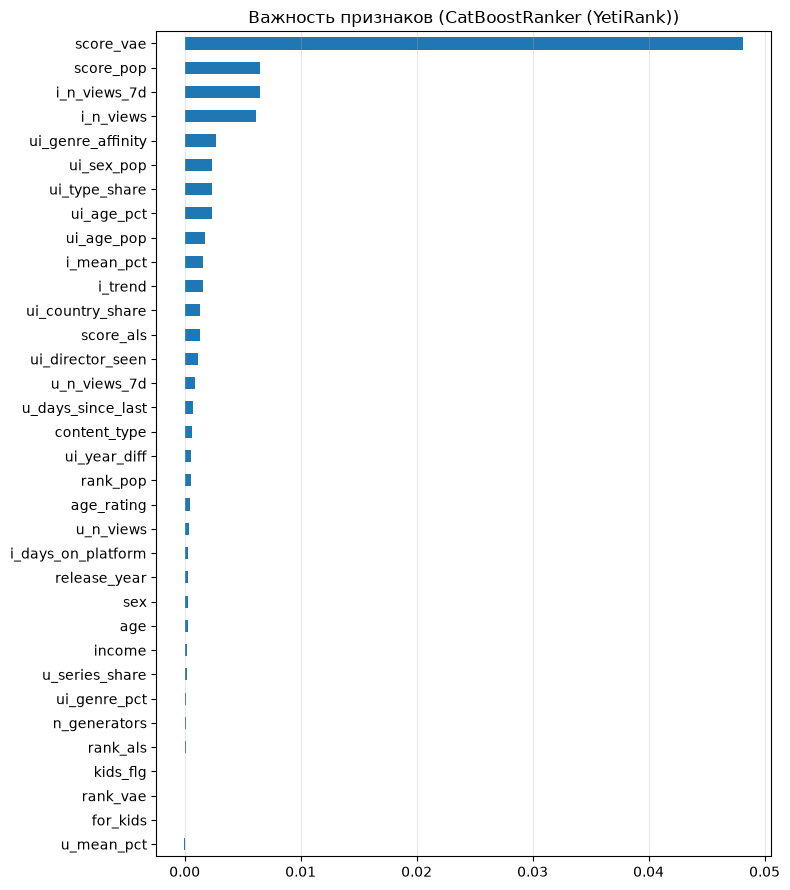

Топ-10 по важности:
score_vae            0.048
score_pop            0.007
i_n_views_7d         0.006
i_n_views            0.006
ui_genre_affinity    0.003
ui_sex_pop           0.002
ui_type_share        0.002
ui_age_pct           0.002
ui_age_pop           0.002
i_mean_pct           0.002
отношение 1-го признака ко 2-му: 7.4 | доля важности у топ-1: 0.524


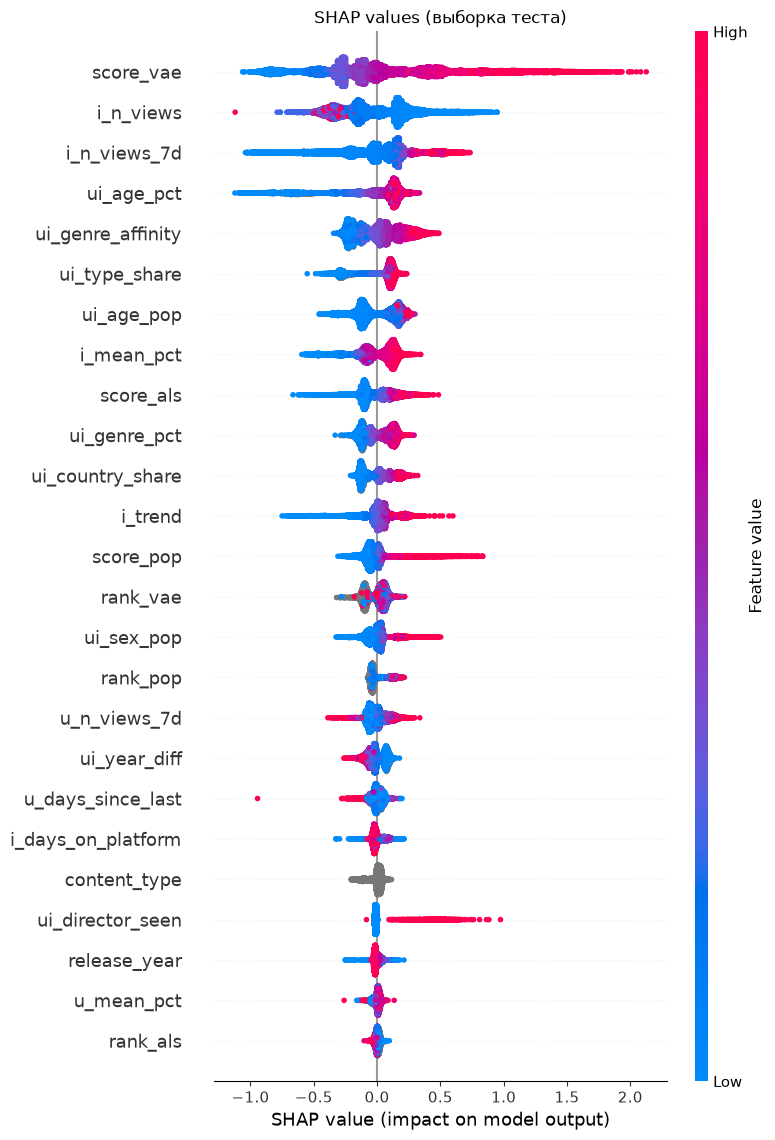

In [19]:
import shap

imp = pd.Series(best_model.get_feature_importance(pool(tr[is_val]) if best_model is ranker else
                                                  Pool(tr[is_val][FEATURES], tr[is_val].target, cat_features=CAT_FEATURES)),
                index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(8, 9))
imp.plot.barh(ax=ax); ax.set_title(f'Важность признаков ({best_name})'); ax.grid(axis='x', alpha=0.3)
plt.tight_layout(); plt.show()
top_imp = imp.sort_values(ascending=False)
print('Топ-10 по важности:'); print(top_imp.head(10).round(3).to_string())
print('отношение 1-го признака ко 2-му:', round(top_imp.iloc[0] / max(top_imp.iloc[1], 1e-9), 2),
      '| доля важности у топ-1:', round(top_imp.iloc[0] / top_imp.sum(), 3))

shap_sample = te.sample(min(20000, len(te)), random_state=SEED).sort_values(['u', 'day'])
shap_pool = Pool(shap_sample[FEATURES], cat_features=CAT_FEATURES,
                 group_id=shap_sample.groupby(['u', 'day']).ngroup() if best_model is ranker else None)
# SHAP-значения считаем встроенным в CatBoost алгоритмом TreeSHAP (то же, что shap.TreeExplainer для CatBoost)
shap_values = best_model.get_feature_importance(shap_pool, type='ShapValues')[:, :-1]   # последний столбец — expected value
shap_X = shap_sample[FEATURES].apply(lambda c: pd.factorize(c)[0] if c.dtype == object else c)   # категории -> коды для раскраски
shap.summary_plot(shap_values, shap_X, max_display=25, show=False)
plt.title('SHAP values (выборка теста)'); plt.tight_layout(); plt.show()

**Интерпретация признаков и проверка на утечки.**
* **`score_vae` — самый важный признак**: 52% суммарной важности, в 7.4 раза больше второго (`score_pop`). Доминирование заметное, но не «в 100 раз». Признак честный: VAE для строк valid обучен только на `train_stage_1`, а для строк теста — только на трейне, то есть на данных до периода.
* **Дальше по важности:**
  * популярность айтема: `score_pop`, `i_n_views_7d`, `i_n_views`;
  * сегментная популярность: `ui_sex_pop`, `ui_age_pop`, `ui_age_pct`;
  * близость к истории юзера: `ui_genre_affinity`, `ui_type_share`, `ui_country_share`, `ui_director_seen`.
* **SHAP-направления осмысленны:**
  * высокая свежая популярность (`i_n_views_7d`, `i_trend`) повышает скор, а высокая популярность за всё время (`i_n_views`) понижает: старые хиты большинство уже посмотрело;
  * высокий процент досмотра айтема в возрастной группе юзера (`ui_age_pct`) и в целом (`i_mean_pct`) повышает вероятность `target = 1`;
  * совпадение жанров, типа контента и режиссёров с историей повышает скор;
  * большая разница в годах выпуска (`ui_year_diff`) и долгий перерыв с последнего визита (`u_days_since_last`) понижают.
* **Подозрительных признаков нет.** `watched_pct` используется только в агрегатах по прошлому. Признаки на его основе (`ui_age_pct`, `i_mean_pct`) получили умеренную важность — и по графику важности, и по SHAP. Почти нулевую важность имеют `u_mean_pct`, `for_kids`, `rank_vae`, `kids_flg`, `rank_als`, `n_generators`, `ui_genre_pct`, `u_series_share`, `income`, `age`. Их можно убрать без потери качества: например, информация `rank_vae` уже содержится в `score_vae`.


### 4 Этап. Инференс лучшего ранкера (max 3 балла)

Теперь мы хотим построить рекомендации "на завтра", для этого нам нужно:

1. Обучить модели первого уровня на всех (train+test) данных (0.5 балла)
2. Для каждой модели первого уровня для каждого пользователя сгененировать N кандидатов (0.5 балла)
3. "Склеить" всех кандидатов для каждого пользователя (дубли выкинуть), посчитать скоры от всех моделей (0.5 балла)
4. Собрать фичи для ваших кандидатов (теперь можем считать признаки на всех данных) (0.5 балла)
5. Проскорить всех кандидатов бустингом и оставить k лучших (0.5 балла)
6. Посчитать разнообразие(Diversity) и построить график от Diversity(k) (0.5 балла)


Все гиперпараметры (N, k) определяете только Вы!

In [20]:
%%time
# ===== Этап 4. Рекомендации «на завтра» для всех пользователей =====
# освобождаем память от выборок и моделей этапов 1–3
for _name in ['train_rows', 'test_rows', 'train_df_with_features', 'test_df_with_features', 'tr', 'te', 'train_pool', 'val_pool',
              'shap_sample', 'shap_values', 'cand_recs', 'my_heuristic_model', 'my_matrix_factorization', 'my_neural_network',
              'stage1_models', 'heur_full', 'als_full', 'vae_full', 'stage1_full', 'hist_test', 'cold_te',
              'va', 'cold_va', 'cold_tr']:
    globals().pop(_name, None)
gc.collect()
full = pd.concat([train, test], ignore_index=True)
TOMORROW = int(full.day.max()) + 1
N_FINAL = dict(pop=30, als=70, vae=70)
K_FINAL = 10      # длина итоговой выдачи
K_DIV = 50        # для графика Diversity(k) сохраняем топ-50

# 1. модели первого уровня на всех данных
heur_all = SegmentPopular().fit(full); timer('heuristic (all data)')
als_all = ALSRecommender(**ALS_PARAMS).fit(full); timer('ALS (all data)')
vae_all = MultVAERecommender(epochs=5 if QUICK else 15).fit(full); timer('Mult-VAE (all data)')
stage1_all = [heur_all, als_all, vae_all]

# все пользователи: и с интеракциями, и только из users.csv (для них — сегментная популярность)
all_users_u = np.arange(N_USERS) if not QUICK else np.unique(full.u.values)
print('пользователей для инференса:', len(all_users_u))

[ 1253.3s] heuristic (all data)


[ 1266.3s] ALS (all data)


[ 1522.3s] Mult-VAE (all data)


пользователей для инференса: 1058084
CPU times: user 1min 4s, sys: 18.3 s, total: 1min 22s
Wall time: 4min 35s


In [21]:
%%time
# 2–5. Кандидаты -> скоры -> признаки (по всем данным, день = завтра) -> бустинг -> top-k. Чанками по юзерам.
CHUNK = 20000 if QUICK else 50000
ctx_tomorrow = day_context(full, TOMORROW)          # вся история до «завтра» — один раз
first_seen_full = first_seen_table(full)
final_top, stats = [], []
for start in tqdm(range(0, len(all_users_u), CHUNK), desc='inference chunks'):
    chunk_users = all_users_u[start:start + CHUNK]
    ud = pd.DataFrame({'u': chunk_users, 'day': TOMORROW})
    rows = make_candidate_rows(ud, stage1_all, first_seen_full, n_per_model=N_FINAL)
    feats = build_features(rows, full, ctx=ctx_tomorrow)
    cold = ~als_all.known_users[feats.u.values]
    pred = (best_model.predict(feats[FEATURES]) if best_model is ranker else best_model.predict_proba(feats[FEATURES])[:, 1])
    if use_cold_ranker and cold.any():
        # холодные юзеры (их нет в данных обучения моделей 1-го уровня) идут через отдельный ранкер
        pred = pred.astype(float)
        pred[cold] = cold_ranker.predict(feats.loc[cold, COLD_FEATURES])
    feats = feats[['u', 'i']].assign(score=pred)
    feats = feats.sort_values(['u', 'score'], ascending=[True, False])
    feats['rank'] = feats.groupby('u').cumcount() + 1
    final_top.append(feats[feats['rank'] <= K_DIV][['u', 'i', 'rank', 'score']])
    stats.append({'users': len(chunk_users), 'candidate_rows': len(rows)})
    del rows, feats; gc.collect()
final_top = pd.concat(final_top, ignore_index=True)
print('строк кандидатов всего:', sum(s['candidate_rows'] for s in stats), '| в среднем на юзера:',
      round(sum(s['candidate_rows'] for s in stats) / len(all_users_u), 1))

recs_tomorrow = (final_top[final_top['rank'] <= K_FINAL]
                 .assign(user_id=lambda x: all_user_ids[x.u.values], item_id=lambda x: all_item_ids[x.i.values])
                 .groupby('user_id').item_id.agg(list).rename('recommendations').reset_index())
recs_tomorrow.to_csv(os.path.join(OUT, 'recommendations_tomorrow.csv'), index=False)
print('сохранено:', os.path.join(OUT, 'recommendations_tomorrow.csv'), recs_tomorrow.shape)
recs_tomorrow.head()

inference chunks:   0%|          | 0/22 [00:00<?, ?it/s]

строк кандидатов всего: 117747750 | в среднем на юзера: 111.3


сохранено: data/final_outputs/recommendations_tomorrow.csv (1058084, 2)
CPU times: user 7min 47s, sys: 32.8 s, total: 8min 20s
Wall time: 7min 10s


,user_id,recommendations
0,0,"[10440, 13865, 3734, 14488, 4151, 142, 11640, ..."
1,1,"[15297, 9728, 4151, 13865, 3734, 142, 14488, 1..."
2,2,"[565, 14530, 9728, 7192, 11919, 8254, 4565, 10..."
3,3,"[13865, 15297, 7310, 9103, 2954, 12356, 11118,..."
4,4,"[9728, 15297, 13865, 10440, 14488, 3734, 9809,..."


  0%|          | 0/10 [00:00<?, ?it/s]

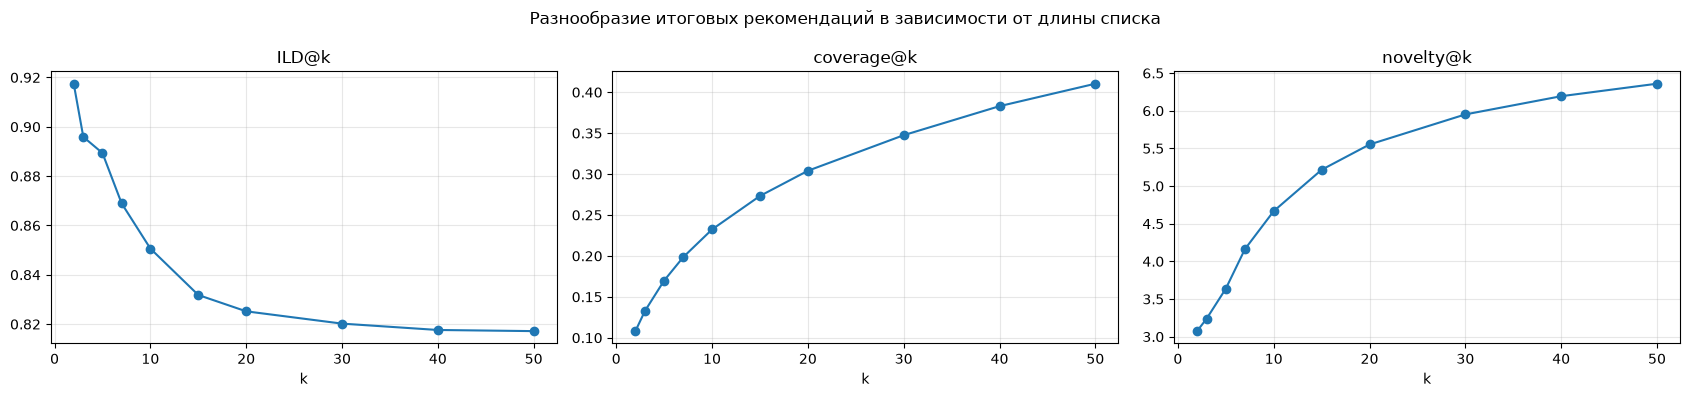

,ILD@k,coverage@k,novelty@k
k,,,
2,0.9175,0.1081,3.0737
3,0.8959,0.1328,3.2393
5,0.8894,0.1699,3.6373
7,0.8690,0.1986,4.1630
10,0.8506,0.2323,4.6671
15,0.8318,0.2733,5.2160
20,0.8252,0.3040,5.5519
30,0.8202,0.3475,5.9512
40,0.8176,0.3829,6.1930


In [22]:
# 6. Diversity(k): ILD (жанровое разнообразие внутри списка), покрытие каталога и новизна для k = 2..50
div_users = np.random.default_rng(SEED).choice(final_top.u.unique(), size=min(20000, final_top.u.nunique()), replace=False)
lists = final_top[final_top.u.isin(div_users)].sort_values(['u', 'rank']).groupby('u').i.agg(list)
item_user_share = np.bincount(full.i, minlength=N_ITEMS) / full.u.nunique()
ks = [2, 3, 5, 7, 10, 15, 20, 30, 40, 50]
div_rows = []
for k in tqdm(ks):
    div_rows.append({'k': k, 'ILD@k': np.nanmean([ild(l[:k]) for l in lists]),
                     'coverage@k': len({i for l in final_top[final_top['rank'] <= k].groupby('u').i.agg(list) for i in l}) / N_ITEMS,
                     'novelty@k': np.nanmean([novelty(l[:k]) for l in lists])})
div = pd.DataFrame(div_rows).set_index('k')

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, col in zip(axes, div.columns):
    ax.plot(div.index, div[col], marker='o'); ax.set_xlabel('k'); ax.set_title(col); ax.grid(alpha=0.3)
plt.suptitle('Разнообразие итоговых рекомендаций в зависимости от длины списка'); plt.tight_layout(); plt.show()
div.round(4)

**Итог этапа 4.**
* **Инференс.** Модели первого уровня переобучены на train + test. Рекомендации «на завтра» построены для **1 058 084 пользователей** — всех из `users.csv` и из интеракций. Это 118 млн строк кандидатов, в среднем 111 на юзера, обработанных чанками по 50 тыс. юзеров. Итоговый топ-10 сохранён в `data/final_outputs/recommendations_tomorrow.csv`.
* **Diversity(k):**
  * ILD@k падает с 0.92 (k = 2) до 0.82 (k = 50). Первые позиции — разные по жанрам главные хиты, глубже идут айтемы, похожие на вкус юзера и, значит, друг на друга.
  * Покрытие каталога растёт с 11% до 41%, новизна — с 3.1 до 6.4: чем глубже, тем менее популярные айтемы.
  * Выбранное k = 10 — компромисс: ILD@10 = 0.85, покрытие 23%.
* **Гиперпараметры:** N кандидатов — pop 30, als 70, vae 70; k = 10. Полный прогон ноутбука на Mac (M3 Max) занимает около 35 минут.